# 08. Cross-Model Matched-Origin Synthesis — Executed Thesis Notebook

**Thesis:** *Towards Trustworthy Financial Time Series Forecasting: An Experimental Evaluation of Explainable Machine Learning Models for Stock Price Prediction*.

## Code Cell 1 — Load, Match, Test, Summarize, and Export

**Purpose.** This notebook reads the seven completed model exports and produces the thesis's cross-model evidence. It does not train, refit, or alter any forecasting model. Its main tasks are to (1) restrict predictions to origins shared by all seven models, (2) recompute comparable accuracy metrics, (3) perform observation-level HAC-Diebold–Mariano tests with multiplicity adjustment, (4) retain separate native-coverage benchmark inference, and (5) synthesize attribution, stability, faithfulness, and seed evidence.

Run this notebook last from the `notebooks/` directory. `BASE` points to `../results/`; `OUT` is `../results/cross_model/`. The stored outputs are retained from execution; documentation was added without recalculating the numerical results.

**How to read the mathematics.** Here $t$ indexes a matched forecast origin, $y_t$ is the realized target, $\hat y_t$ is a model prediction, and $\phi_{i,j}$ is an attribution for probe $i$ and feature $j$. The text around each equation defines the remaining symbols, explains the computation, and states its interpretation limits.

### 1. Inputs, constants, and file checks

`MODEL_DIRS` fixes the seven model order: Linear, ARIMA, RandomForest, XGBoost, LightGBM, LSTM, and TFT. `read_table()` reads a named CSV from a model's `tables/` folder and stops with `FileNotFoundError` if an input is absent. The analysis uses two horizons, two schemes, four financial series plus Sunspot, and a 0.05 false-discovery-rate threshold.

All seven `observation_predictions.csv` files are concatenated. Assertions require 188,160 native prediction rows, the expected model label inside each file, and no duplicate model–series–horizon–scheme–fold–origin key. These checks prevent a missing or repeated export from silently changing the comparison.

### 2. Why common origins are required

Static notebooks normally export 252 test origins per fold, whereas deep notebooks export 231 after lookback construction. Comparing their native RMSE values directly would mix model differences with differences in evaluation periods. The synthesis therefore defines origin keys as series, horizon, scheme, origin index, origin date, and target date, then retains only keys at which exactly seven models are present.

The resulting all-seven intersection contains **18,480 matched origins** and **129,360 matched prediction rows** (seven predictions per origin). Each series–horizon–scheme cell contains **924 origins**, and each matched fold contains **231**. Rolling static folds 2–5 align to deep folds 0–3; expanding folds 0–3 align directly. The LSTM fold labels supply the common matched-fold mapping.

This equalizes evaluation coverage. It does **not** equalize training information sets, hyperparameter tuning effort, model complexity, or stochastic replication. Rolling and expanding results remain related robustness analyses rather than independent samples.

### 3. Matched metrics and rankings

For every model–series–horizon–scheme cell, the code recomputes

$$
\mathrm{RMSE}=\sqrt{\frac1n\sum_t(y_t-\hat y_t)^2},\qquad
\mathrm{MAE}=\frac1n\sum_t|y_t-\hat y_t|,
$$

$$
R^2=1-\frac{\sum_t(y_t-\hat y_t)^2}{\sum_t(y_t-\bar y)^2},\qquad
\mathrm{DA}=\frac1n\sum_t\mathbf1\{\operatorname{sign}(y_t)=\operatorname{sign}(\hat y_t)\}.
$$

Here $n$ is the number of evaluated origins, $\bar y$ is the realized-target mean within the evaluation sample, and $\mathbf{1}\{\cdot\}$ equals one when the stated condition holds and zero otherwise. RMSE and MAE measure forecast-error magnitude, $R^2$ compares squared error with an evaluation-sample mean benchmark, and DA measures sign agreement.

DA is undefined for Sunspot. Relative RMSE divides model RMSE by persistence RMSE and, separately, by training-mean RMSE. Financial persistence is zero cumulative future log return; Sunspot persistence is the current native value. Values below one indicate lower RMSE than the named benchmark. `mean_rmse_rank` ranks the seven models within each cell using minimum ranks for ties. Fold-level matched metrics are also recomputed for each matched fold.

### 4. Block-aware observation-level HAC-DM inference

For each of 20 series–horizon–scheme cells, squared errors are pivoted into seven model columns. All 21 unordered model pairs are tested, yielding **420 comparisons overall** and **336 financial comparisons**. For pair A versus B,

$$
d_t=(y_t-\hat y_{A,t})^2-(y_t-\hat y_{B,t})^2.
$$

A negative mean differential favors model A. `dm_hac_observation()` computes

$$
DM=\frac{\bar d}{\sqrt{\hat S/n}},\qquad p=2[1-\Phi(|DM|)],
\qquad
\hat S=\hat\gamma_0+2\sum_{k=1}^{h-1}\hat\gamma_k.
$$

In these expressions, $\bar d$ is the mean loss differential, $\hat S$ estimates the long-run variance of that differential, $\hat\gamma_k$ is the lag-$k$ autocovariance, and $\Phi$ is the standard normal cumulative distribution function. The p-value is two-sided and describes evidence about a loss difference; it does not measure economic importance.

The key detail is `segments`: autocovariance products are calculated **only inside each contiguous matched forecast block**, then summed across blocks. They never join the end of one fold to the start of another. The HAC lag is zero at horizon 1 and four at horizon 5, with no Bartlett weighting. Fewer than 20 observations or invalid/non-positive variance produces missing values.

`bh()` applies Benjamini–Hochberg adjustment separately to the 21 pairs in each cell. Ordered p-values are multiplied by $m/i$, made monotone by a reverse cumulative minimum, and capped at one. `significant_q05` marks adjusted p-values below 0.05. Statistical significance and effect direction are retained separately; a nonsignificant result is not proof that two models are equivalent.

### 5. Supplementary native-coverage benchmark tests

The primary matched ranking is kept separate from native-coverage evidence. `native_fold_metrics` concatenates all **760** native fold-metric rows. For each model–series–horizon–scheme cell, the code compares model squared loss with persistence and the supervised training mean while retaining every native origin. Autocovariances remain inside each native fold block.

There are 280 model–benchmark tests: seven models × two benchmarks × 20 cells. Static cells contain 1,512 origins and deep cells 924, so these are not seven-way matched rankings. `p_bh_14_tests` adjusts all 14 model–benchmark tests within each series–horizon–scheme cell. Outcomes are classified as model win, model loss, or not significant using both significance and DM sign.

The code also merges each model notebook's original two-test, unsegmented export as a sensitivity analysis. `native_benchmark_summary` aggregates raw lower-loss counts and significant outcomes under both multiplicity families. Keeping BH14 and BH2 distinct prevents two different inferential procedures from being presented as interchangeable.

### 6. Attribution, stability, and regime synthesis

All model attribution tables are concatenated. Within each model–probe–method vector, relative absolute attribution is

$$
r_{i,j}=\frac{|\phi_{i,j}|}{\sum_k|\phi_{i,k}|},
$$

provided the denominator is positive. This normalization makes relative reliance comparable across target scales, but it discards sign and absolute magnitude. Summaries are produced by model, method, sample, series, horizon, scheme, and feature, and then by model and sample.

Stability tables are pooled without changing their probe-level definitions. The code reports median and mean Spearman correlation, the 10th percentile, median cosine similarity, top-feature agreement, and counts. `stability_by_scheme` preserves rolling/expanding differences. `regime_wide` subtracts the boundary median from bear, bull, and crisis medians. These are descriptive regime contrasts, not structural-break tests or independent crisis-event studies.

### 7. Faithfulness and seed sensitivity

`numeric_value()` converts stored booleans to 1/0 and other entries to numeric values where possible. Faithfulness summaries retain count, mean, median, minimum, and maximum for every model–method–metric combination. This includes additivity residuals, PFI–SHAP and LIME-style–SHAP rank agreement, surrogate holdout MSE, deletion/insertion areas and success indicators, and native–post-hoc agreement where available.

Only Random Forest, XGBoost, and LightGBM contribute `seed_stability` tables. Their two-seed summaries are not extended to LSTM or TFT because no equivalent repeated-seed neural experiment was conducted. Forecast diagnostics, ARIMA native parameters, and TFT native signals are also consolidated without changing their model-specific meanings.

### 8. Model summaries and figures

`model_summary`, `financial_summary`, and `sunspot_summary` aggregate matched metrics. Financial and Sunspot scales are normalized within each cell before model-level averaging, preventing Sunspot's native units from dominating a raw RMSE average. Mean directional accuracy and mean $R^2$ are computed only from financial cells for the financial summary.

Five figures are exported:

1. matched financial RMSE relative to zero-return persistence, by rolling/expanding scheme;
2. matched financial directional accuracy, with a 50% reference line;
3. primary-channel financial attribution stability by ex post regime;
4. deletion/insertion success rates, with ARIMA marked not applicable for these generic interventions;
5. mean within-probe relative absolute financial attribution.

Figures communicate the tables; they are not independent evidence. Directional accuracy is not profitability, and relative attribution is not causal economic importance.

### 9. Evidence summary, exports, and validation

`analysis_summary.json` records row counts, best-RMSE models by cell, financial and Sunspot metrics, stability and regime summaries, faithfulness, relative importance, seed stability, native benchmark outcomes, and the causal-identification boundary. The `tables` dictionary exports matched predictions and metrics, pairwise and benchmark inference, native fold metrics, attributions, stability, faithfulness, seed summaries, diagnostics, and model-specific native signals.

A final assertion block checks seven input tables, 188,160 native predictions, 760 native fold rows, 18,480 matched origins, 129,360 matched predictions, 924 origins per cell, 231 origins per matched fold, exactly seven models per origin, 21 pairs per cell, complete BH values, 280 native benchmark tests, 14 tests per cell, and the explicit economic-identification boundary. `validation.json` stores these checks. `provenance.json` records source locations, environment, matching logic, DM construction, and native benchmark semantics.

**Research-question mapping.** RQ1 is addressed by matched accuracy and pairwise/native benchmark inference; RQ2 by fold, scheme, regime, and tree-seed stability summaries; RQ3 by additivity, interventions, cross-channel agreement, native signals, and relative attribution. The synthesis supplies evidence for §5.1–§5.4, Chapter 6's conditional answers, Chapter 7's limitations, and Chapter 8's conclusion.

**Thesis and literature connection:** §4.5–§4.6 define the evaluation procedures; Appendices A–D contain the full evidence and reproducibility context. Relevant thesis literature includes Diebold (2007) for forecast evaluation; Ballarin (2024), Medeiros (2022), López de Prado (2018), and Hu et al. (2026) for temporal evaluation rigor; Molnar (2022), Biecek and Burzykowski (2021), Theissler et al. (2022), Theissler (2024), and Arsenault, Wang, and Patenaude (2025) for explanation evaluation; Cochrane (2005) for the distinction between statistical prediction and economic mechanisms.

**Overall interpretation boundary.** The results can support or weaken specific accuracy, stability, and faithfulness claims under this design. They cannot establish universal black-box superiority, universal crisis degradation, complete faithfulness from additivity, investment profitability from directional accuracy, or genuine causal economic drivers from four lag channels.


In [1]:
# Independent common-origin synthesis of the seven executed model notebooks.
from pathlib import Path
import json, hashlib, itertools, platform, sys
from datetime import datetime, timezone
import numpy as np
import pandas as pd
from scipy.stats import norm, spearmanr
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

BASE = Path.cwd().parent / 'results'
OUT = BASE / 'cross_model'
for sub in ('tables', 'figures', 'evidence'):
    (OUT / sub).mkdir(parents=True, exist_ok=True)
MODEL_DIRS = {'Linear': 'Linear_study', 'ARIMA': 'ARIMA_study', 'RandomForest': 'RandomForest_study',
              'XGBoost': 'XGBoost_study', 'LightGBM': 'LightGBM_study', 'LSTM': 'LSTM_study', 'TFT': 'TFT_study'}
MODEL_ORDER = list(MODEL_DIRS)
FINANCIAL = ['sp500', 'dax', 'nasdaq', 'djia']
HORIZONS = [1, 5]
SCHEMES = ['rolling', 'expanding']
Q = 0.05


def read_table(model, name):
    path = BASE / MODEL_DIRS[model] / 'tables' / f'{name}.csv'
    if not path.exists():
        raise FileNotFoundError(path)
    return pd.read_csv(path, low_memory=False)


def dm_hac_observation(loss_a, loss_b, horizon, segments=None):
    differential = np.asarray(loss_a, float) - np.asarray(loss_b, float)
    n = len(differential)
    centered = differential - differential.mean()
    if segments is None:
        segments = np.zeros(n, dtype=int)
    segments = np.asarray(segments)
    # Estimate autocovariances only within contiguous matched forecast blocks.
    variance = 0.0
    max_lag = min(max(horizon - 1, 0), 9)
    covariance_sums = np.zeros(max_lag + 1)
    for segment in np.unique(segments):
        block = centered[segments == segment]
        covariance_sums[0] += np.dot(block, block)
        for lag in range(1, max_lag + 1):
            covariance_sums[lag] += np.dot(block[lag:], block[:-lag]) if len(block) > lag else 0.0
    variance = covariance_sums[0] / n + 2 * covariance_sums[1:].sum() / n
    if n < 20 or not np.isfinite(variance) or variance <= 0:
        return np.nan, np.nan
    statistic = differential.mean() / np.sqrt(variance / n)
    return float(statistic), float(2 * (1 - norm.cdf(abs(statistic))))


def bh(p_values):
    p = np.asarray(p_values, float)
    adjusted = np.full(len(p), np.nan)
    valid = np.flatnonzero(np.isfinite(p))
    if not len(valid):
        return adjusted
    order = valid[np.argsort(p[valid])]
    ranked = p[order] * len(order) / np.arange(1, len(order) + 1)
    ranked = np.minimum.accumulate(ranked[::-1])[::-1]
    adjusted[order] = np.minimum(ranked, 1.0)
    return adjusted


prediction_parts = []
for model in MODEL_ORDER:
    part = read_table(model, 'observation_predictions')
    assert set(part['model']) == {model}
    prediction_parts.append(part)
predictions = pd.concat(prediction_parts, ignore_index=True)
assert len(predictions) == 188160, len(predictions)
assert not predictions.duplicated(['model', 'series', 'horizon', 'scheme', 'fold', 'origin_index']).any()

origin_keys = ['series', 'horizon', 'scheme', 'origin_index', 'origin_date', 'target_date']
model_counts = predictions.groupby(origin_keys)['model'].nunique().rename('n_models').reset_index()
common_origins = model_counts[model_counts['n_models'] == 7][origin_keys]
matched = predictions.merge(common_origins, on=origin_keys, how='inner', validate='many_to_one')
deep_folds = predictions[predictions['model'] == 'LSTM'][origin_keys + ['fold']].rename(columns={'fold': 'matched_fold'})
matched = matched.merge(deep_folds, on=origin_keys, how='left', validate='many_to_one')
assert len(common_origins) == 18480, len(common_origins)
assert len(matched) == 129360, len(matched)
counts = matched.groupby(['series', 'horizon', 'scheme'])['origin_index'].nunique()
assert (counts == 924).all(), counts
fold_counts = matched.groupby(['series', 'horizon', 'scheme', 'matched_fold'])['origin_index'].nunique()
assert (fold_counts == 231).all(), fold_counts
assert matched.groupby(origin_keys)['model'].nunique().eq(7).all()

metric_rows = []
for (model, sid, horizon, scheme), group in matched.groupby(['model', 'series', 'horizon', 'scheme']):
    group = group.sort_values('origin_index')
    persistence_rmse = np.sqrt(mean_squared_error(group['y_true'], group['random_walk_pred']))
    mean_rmse = np.sqrt(mean_squared_error(group['y_true'], group['train_mean_pred']))
    metric_rows.append({'model': model, 'series': sid, 'horizon': horizon, 'scheme': scheme,
                        'n': len(group), 'rmse': np.sqrt(mean_squared_error(group['y_true'], group['y_pred'])),
                        'mae': mean_absolute_error(group['y_true'], group['y_pred']),
                        'r2': r2_score(group['y_true'], group['y_pred']),
                        'da': np.mean(np.sign(group['y_true']) == np.sign(group['y_pred'])) if sid != 'monash_sunspot' else np.nan,
                        'persistence_rmse': persistence_rmse, 'train_mean_rmse': mean_rmse,
                        'rmse_relative_to_persistence': np.sqrt(mean_squared_error(group['y_true'], group['y_pred'])) / persistence_rmse,
                        'rmse_relative_to_train_mean': np.sqrt(mean_squared_error(group['y_true'], group['y_pred'])) / mean_rmse})
matched_metrics = pd.DataFrame(metric_rows)
matched_metrics['mean_rmse_rank'] = matched_metrics.groupby(['series', 'horizon', 'scheme'])['rmse'].rank(method='min')

fold_metric_rows = []
for (model, sid, horizon, scheme, fold), group in matched.groupby(['model', 'series', 'horizon', 'scheme', 'matched_fold']):
    fold_metric_rows.append({'model': model, 'series': sid, 'horizon': horizon, 'scheme': scheme, 'matched_fold': fold,
                             'n': len(group), 'rmse': np.sqrt(mean_squared_error(group['y_true'], group['y_pred'])),
                             'mae': mean_absolute_error(group['y_true'], group['y_pred']),
                             'r2': r2_score(group['y_true'], group['y_pred']),
                             'da': np.mean(np.sign(group['y_true']) == np.sign(group['y_pred'])) if sid != 'monash_sunspot' else np.nan})
matched_fold_metrics = pd.DataFrame(fold_metric_rows)

pair_rows = []
for (sid, horizon, scheme), cell in matched.groupby(['series', 'horizon', 'scheme']):
    wide = cell.pivot(index='origin_index', columns='model', values='squared_error').dropna()
    segment_map = cell.drop_duplicates('origin_index').set_index('origin_index')['matched_fold']
    segments = segment_map.loc[wide.index].values
    assert list(wide.columns) == sorted(wide.columns)
    assert len(wide) == 924
    for model_a, model_b in itertools.combinations(MODEL_ORDER, 2):
        statistic, p_value = dm_hac_observation(wide[model_a], wide[model_b], horizon, segments)
        pair_rows.append({'series': sid, 'horizon': horizon, 'scheme': scheme, 'model_a': model_a, 'model_b': model_b,
                          'n': len(wide), 'mean_squared_error_a': wide[model_a].mean(), 'mean_squared_error_b': wide[model_b].mean(),
                          'dm_statistic_a_minus_b': statistic, 'p_raw': p_value,
                          'lower_loss_model': model_a if wide[model_a].mean() < wide[model_b].mean() else model_b})
dm_pairs = pd.DataFrame(pair_rows)
dm_pairs['p_bh_21_pairs'] = np.nan
for _, indices in dm_pairs.groupby(['series', 'horizon', 'scheme']).groups.items():
    dm_pairs.loc[indices, 'p_bh_21_pairs'] = bh(dm_pairs.loc[indices, 'p_raw'])
dm_pairs['significant_q05'] = dm_pairs['p_bh_21_pairs'] < Q
assert len(dm_pairs) == 20 * 21

# Native-coverage fold metrics remain separate from the common-origin primary comparison.
native_fold_metrics = pd.concat([read_table(model, 'fold_metrics') for model in MODEL_ORDER], ignore_index=True)
assert len(native_fold_metrics) == 760
benchmark_dm = pd.concat([read_table(model, 'benchmark_dm') for model in MODEL_ORDER], ignore_index=True)

# Supplementary native-coverage benchmark inference. These tests retain every
# native origin, so static n=1,512 and deep n=924 are deliberately not used for
# seven-way rankings. HAC autocovariances remain within each native fold block.
native_benchmark_block_rows = []
for (model, sid, horizon, scheme), group in predictions.groupby(['model', 'series', 'horizon', 'scheme']):
    group = group.sort_values('origin_index')
    for comparison, column in [('random_walk_or_persistence', 'random_walk_pred'),
                               ('training_mean', 'train_mean_pred')]:
        benchmark_loss = (group['y_true'] - group[column]) ** 2
        statistic, p_value = dm_hac_observation(group['squared_error'], benchmark_loss, horizon, group['fold'])
        native_benchmark_block_rows.append({
            'model': model, 'series': sid, 'horizon': horizon, 'scheme': scheme,
            'comparison': comparison, 'n': int(len(group)), 'dm': statistic, 'p_raw': p_value})
native_benchmark_block = pd.DataFrame(native_benchmark_block_rows)
native_benchmark_block['p_bh_14_tests'] = np.nan
for _, indices in native_benchmark_block.groupby(['series', 'horizon', 'scheme']).groups.items():
    assert len(indices) == 14  # seven models against two benchmarks
    native_benchmark_block.loc[indices, 'p_bh_14_tests'] = bh(native_benchmark_block.loc[indices, 'p_raw'])
native_benchmark_block['significant_q05'] = native_benchmark_block['p_bh_14_tests'] < Q
native_benchmark_block['outcome'] = np.select(
    [native_benchmark_block['significant_q05'] & (native_benchmark_block['dm'] < 0),
     native_benchmark_block['significant_q05'] & (native_benchmark_block['dm'] > 0)],
    ['model_win', 'model_loss'], default='not_significant')
native_benchmark_block['sample'] = np.where(native_benchmark_block['series'] == 'monash_sunspot', 'sunspot', 'financial')
benchmark_keys = ['model', 'series', 'horizon', 'scheme', 'comparison']
native_benchmark_block = native_benchmark_block.merge(
    benchmark_dm[benchmark_keys + ['dm', 'p_raw', 'p_bh_within_series_horizon_scheme']].rename(columns={
        'dm': 'dm_unsegmented', 'p_raw': 'p_raw_unsegmented',
        'p_bh_within_series_horizon_scheme': 'p_bh_exported_2_tests'}),
    on=benchmark_keys, how='left', validate='one_to_one')
native_benchmark_block['significant_exported_bh2'] = native_benchmark_block['p_bh_exported_2_tests'] < Q
native_benchmark_block['outcome_exported_bh2'] = np.select(
    [native_benchmark_block['significant_exported_bh2'] & (native_benchmark_block['dm_unsegmented'] < 0),
     native_benchmark_block['significant_exported_bh2'] & (native_benchmark_block['dm_unsegmented'] > 0)],
    ['model_win', 'model_loss'], default='not_significant')
native_benchmark_summary = (native_benchmark_block.groupby(['sample', 'model', 'comparison'])
    .agg(tests=('dm', 'size'),
         raw_lower_loss=('dm', lambda values: int((values < 0).sum())),
         significant_wins=('outcome', lambda values: int(values.eq('model_win').sum())),
         significant_losses=('outcome', lambda values: int(values.eq('model_loss').sum())),
         not_significant=('outcome', lambda values: int(values.eq('not_significant').sum())),
         exported_bh2_wins=('outcome_exported_bh2', lambda values: int(values.eq('model_win').sum())),
         exported_bh2_losses=('outcome_exported_bh2', lambda values: int(values.eq('model_loss').sum())))
    .reset_index())
assert len(native_benchmark_block) == 280
assert native_benchmark_block.groupby(['series', 'horizon', 'scheme']).size().eq(14).all()

attributions = pd.concat([read_table(model, 'attributions') for model in MODEL_ORDER], ignore_index=True)
attributions['sample'] = np.where(attributions['series'] == 'monash_sunspot', 'sunspot', 'financial')
attributions['abs_attribution'] = attributions['attribution'].abs()
probe_keys = ['model', 'series', 'horizon', 'scheme', 'fold', 'method', 'probe']
totals = attributions.groupby(probe_keys)['abs_attribution'].transform('sum')
attributions['relative_abs_attribution'] = np.where(totals > 0, attributions['abs_attribution'] / totals, np.nan)
relative_importance = (attributions.groupby(['model', 'method', 'sample', 'series', 'horizon', 'scheme', 'feature'])
                       ['relative_abs_attribution'].agg(['mean', 'median', 'std', 'count']).reset_index())
model_importance = (attributions.groupby(['model', 'method', 'sample', 'feature'])['relative_abs_attribution']
                    .agg(['mean', 'median', 'std', 'count']).reset_index())

stability = pd.concat([read_table(model, 'stability') for model in MODEL_ORDER], ignore_index=True)
stability['sample'] = np.where(stability['series'] == 'monash_sunspot', 'sunspot', 'financial')
stability_summary = (stability.groupby(['model', 'method', 'sample', 'regime'])
                     .agg(rho_median=('rho', 'median'), rho_mean=('rho', 'mean'), rho_p10=('rho', lambda x: x.quantile(.1)),
                          cosine_median=('cosine', 'median'), top1_match_rate=('top1_match', 'mean'),
                          count=('rho', 'size')).reset_index())
stability_by_scheme = (stability.groupby(['model', 'method', 'sample', 'scheme', 'regime'])
                       .agg(rho_median=('rho', 'median'), cosine_median=('cosine', 'median'),
                            top1_match_rate=('top1_match', 'mean'), count=('rho', 'size')).reset_index())
regime_wide = stability_summary.pivot_table(index=['model', 'method', 'sample'], columns='regime', values='rho_median').reset_index()
for regime in ['bear', 'bull', 'crisis']:
    if regime in regime_wide and 'boundary' in regime_wide:
        regime_wide[f'{regime}_minus_boundary'] = regime_wide[regime] - regime_wide['boundary']

faithfulness = pd.concat([read_table(model, 'faithfulness') for model in MODEL_ORDER], ignore_index=True)

def numeric_value(value):
    if isinstance(value, (bool, np.bool_)):
        return float(value)
    if str(value) == 'True':
        return 1.0
    if str(value) == 'False':
        return 0.0
    return pd.to_numeric(value, errors='coerce')

faithfulness['value_numeric'] = faithfulness['value'].map(numeric_value)
faithfulness_summary = (faithfulness.groupby(['model', 'method', 'metric'])['value_numeric']
                        .agg(['count', 'mean', 'median', 'min', 'max']).reset_index())
seed_stability = pd.concat([read_table(model, 'seed_stability') for model in ['RandomForest', 'XGBoost', 'LightGBM']], ignore_index=True)
seed_stability['sample'] = np.where(seed_stability['series'] == 'monash_sunspot', 'sunspot', 'financial')
seed_stability_summary = (seed_stability.groupby(['model', 'sample', 'regime'])
                          .agg(rho_median=('rho', 'median'), top1_match_rate=('top1_match', 'mean'), count=('rho', 'size')).reset_index())
forecast_diagnostics = pd.concat([read_table(model, 'forecast_diagnostics').assign(model=model) for model in MODEL_ORDER], ignore_index=True)
native_params = read_table('ARIMA', 'native_params')
tft_native_signals = read_table('TFT', 'native_signals')

# Model-level primary diagnostics. Financial and Sunspot scales are normalized within each cell before averaging.
model_summary = (matched_metrics.groupby('model')
                 .agg(mean_relative_rmse=('rmse_relative_to_persistence', 'mean'),
                      median_relative_rmse=('rmse_relative_to_persistence', 'median'),
                      mean_rank=('mean_rmse_rank', 'mean'), mean_da=('da', 'mean')).reset_index())
financial_summary = (matched_metrics[matched_metrics['series'] != 'monash_sunspot'].groupby('model')
                     .agg(mean_relative_rmse=('rmse_relative_to_persistence', 'mean'),
                          median_relative_rmse=('rmse_relative_to_persistence', 'median'),
                          mean_rank=('mean_rmse_rank', 'mean'), mean_da=('da', 'mean'),
                          mean_r2=('r2', 'mean')).reset_index())
sunspot_summary = matched_metrics[matched_metrics['series'] == 'monash_sunspot'].copy()

# Figures: primary accuracy, stability, faithfulness, and relative attribution evidence.
plt.rcParams.update({'figure.dpi': 130, 'font.size': 9})
financial_metrics = matched_metrics[matched_metrics['series'] != 'monash_sunspot'].copy()
financial_metrics['cell'] = financial_metrics['series'] + ' h' + financial_metrics['horizon'].astype(str)
fig, axes = plt.subplots(1, 2, figsize=(16, 6), constrained_layout=True)
for ax, scheme in zip(axes, SCHEMES):
    pivot = financial_metrics[financial_metrics['scheme'] == scheme].pivot(index='model', columns='cell', values='rmse_relative_to_persistence').reindex(MODEL_ORDER)
    image = ax.imshow(pivot.values, aspect='auto', cmap='RdYlGn_r', vmin=min(.85, np.nanmin(pivot.values)), vmax=max(1.15, np.nanmax(pivot.values)))
    ax.set_xticks(range(len(pivot.columns)), pivot.columns, rotation=45, ha='right')
    ax.set_yticks(range(len(pivot.index)), pivot.index)
    ax.set_title(f'{scheme.title()} walk-forward')
    for i in range(pivot.shape[0]):
        for j in range(pivot.shape[1]):
            ax.text(j, i, f'{pivot.iloc[i, j]:.3f}', ha='center', va='center', fontsize=7)
    fig.colorbar(image, ax=ax, shrink=.75, label='RMSE / zero-return RMSE')
fig.suptitle('Matched-origin financial forecast accuracy (924 origins per cell)')
fig.savefig(OUT / 'figures' / 'matched_financial_relative_rmse.png', bbox_inches='tight')
plt.close(fig)

fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
plot_data = financial_summary.set_index('model').reindex(MODEL_ORDER)
ax.bar(plot_data.index, plot_data['mean_da'])
ax.axhline(.5, color='black', linestyle='--', linewidth=1)
ax.set_ylabel('Mean directional accuracy across financial cells')
ax.set_title('Matched-origin directional accuracy')
ax.tick_params(axis='x', rotation=35)
fig.savefig(OUT / 'figures' / 'matched_financial_directional_accuracy.png', bbox_inches='tight')
plt.close(fig)

primary_methods = {'Linear': 'exact_linear_SHAP', 'ARIMA': 'ARIMA_native_counterfactual_lag',
                   'RandomForest': 'TreeSHAP_full_ensemble', 'XGBoost': 'TreeSHAP_full_ensemble',
                   'LightGBM': 'TreeSHAP_full_ensemble', 'LSTM': 'KernelSHAP_lag_aggregated', 'TFT': 'KernelSHAP_lag_aggregated'}
primary_stability = stability_summary[(stability_summary['sample'] == 'financial') &
                                      stability_summary.apply(lambda row: row['method'] == primary_methods[row['model']], axis=1)]
fig, ax = plt.subplots(figsize=(12, 6), constrained_layout=True)
regimes = ['bear', 'boundary', 'bull', 'crisis']
width = .8 / len(MODEL_ORDER)
for i, model in enumerate(MODEL_ORDER):
    subset = primary_stability[primary_stability['model'] == model].set_index('regime')
    ax.bar(np.arange(len(regimes)) + i * width, [subset['rho_median'].get(regime, np.nan) for regime in regimes], width=width, label=model)
ax.set_xticks(np.arange(len(regimes)) + .4 - width / 2, regimes)
ax.set_ylabel('Median consecutive-fold Spearman correlation')
ax.set_title('Financial attribution stability by ex post regime stratum')
ax.legend(ncol=4, fontsize=8)
fig.savefig(OUT / 'figures' / 'financial_stability_by_regime.png', bbox_inches='tight')
plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
for ax, metric, title in [(axes[0], 'faithful_deletion', 'Deletion worse than random mean'),
                          (axes[1], 'faithful_insertion', 'Insertion better than random mean')]:
    subset = faithfulness[faithfulness['metric'] == metric]
    rates = subset.groupby('model')['value_numeric'].mean().reindex(MODEL_ORDER)
    ax.bar(rates.index, rates.values)
    ax.set_ylim(0, 1)
    ax.set_title(title)
    ax.tick_params(axis='x', rotation=35)
fig.suptitle('Faithfulness intervention diagnostics (ARIMA not applicable)')
fig.savefig(OUT / 'figures' / 'faithfulness_interventions.png', bbox_inches='tight')
plt.close(fig)

fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
importance_pivot = model_importance[model_importance['sample'] == 'financial'].pivot_table(index='model', columns='feature', values='mean').reindex(MODEL_ORDER)[['lag_1', 'lag_5', 'lag_21', 'lag_252']]
image = ax.imshow(importance_pivot.values, aspect='auto', cmap='viridis')
ax.set_xticks(range(4), importance_pivot.columns)
ax.set_yticks(range(len(MODEL_ORDER)), MODEL_ORDER)
for i in range(importance_pivot.shape[0]):
    for j in range(importance_pivot.shape[1]):
        ax.text(j, i, f'{importance_pivot.iloc[i, j]:.3f}', ha='center', va='center', color='white' if importance_pivot.iloc[i, j] < np.nanmax(importance_pivot.values) * .65 else 'black')
ax.set_title('Mean within-probe relative absolute attribution — financial series')
fig.colorbar(image, ax=ax, shrink=.8)
fig.savefig(OUT / 'figures' / 'financial_relative_attribution.png', bbox_inches='tight')
plt.close(fig)

# Data-derived evidence summary used by the thesis and independent claim checks.
def records(frame):
    return json.loads(frame.to_json(orient='records'))

best_rows = matched_metrics.loc[matched_metrics.groupby(['series', 'horizon', 'scheme'])['rmse'].idxmin()]
significant_pairs = dm_pairs[dm_pairs['significant_q05']]
additivity = faithfulness[faithfulness['metric'].isin(['max_abs_residual'])].groupby('model')['value_numeric'].agg(['max', 'median']).reset_index()
summary = {
    'execution_utc': datetime.now(timezone.utc).isoformat(),
    'prediction_rows_native': int(len(predictions)), 'matched_origin_count': int(len(common_origins)),
    'matched_prediction_rows': int(len(matched)), 'origins_per_series_horizon_scheme': int(counts.iloc[0]),
    'origins_per_matched_fold': int(fold_counts.iloc[0]), 'dm_pairwise_tests': int(len(dm_pairs)),
    'dm_significant_pairs_q05': int(len(significant_pairs)),
    'best_rmse_by_cell': records(best_rows[['model', 'series', 'horizon', 'scheme', 'rmse', 'rmse_relative_to_persistence']]),
    'financial_model_summary': records(financial_summary), 'sunspot_model_metrics': records(sunspot_summary),
    'stability_summary': records(stability_summary), 'regime_contrasts': records(regime_wide),
    'faithfulness_summary': records(faithfulness_summary), 'additivity_summary': records(additivity),
    'relative_importance': records(model_importance), 'seed_stability_summary': records(seed_stability_summary),
    'native_benchmark_summary': records(native_benchmark_summary),
    'identification_boundary': 'Lagged prices or native Sunspot values alone cannot identify genuine causal economic drivers; RQ3 economic-driver claims remain unsupported by the design.'
}

tables = {'matched_observation_predictions': matched, 'matched_metrics': matched_metrics,
          'matched_fold_metrics': matched_fold_metrics, 'dm_pairwise': dm_pairs,
          'native_fold_metrics': native_fold_metrics, 'native_benchmark_dm': benchmark_dm,
          'native_benchmark_block_dm': native_benchmark_block, 'native_benchmark_summary': native_benchmark_summary,
          'attributions': attributions, 'relative_importance_by_cell': relative_importance,
          'relative_importance_by_model': model_importance, 'stability': stability,
          'stability_summary': stability_summary, 'stability_by_scheme': stability_by_scheme,
          'regime_contrasts': regime_wide, 'faithfulness': faithfulness,
          'faithfulness_summary': faithfulness_summary, 'seed_stability_summary': seed_stability_summary,
          'forecast_diagnostics': forecast_diagnostics, 'arima_native_params': native_params,
          'tft_native_signals': tft_native_signals, 'model_summary': model_summary,
          'financial_model_summary': financial_summary}
for name, table in tables.items():
    table.to_csv(OUT / 'tables' / f'{name}.csv', index=False)
(OUT / 'evidence' / 'analysis_summary.json').write_text(json.dumps(summary, indent=2, default=str))

# Independent numerical and artifact checks.
validation = {
    'all_seven_notebook_prediction_tables_present': len(prediction_parts) == 7,
    'native_prediction_row_count_188160': len(predictions) == 188160,
    'native_fold_metric_row_count_760': len(native_fold_metrics) == 760,
    'matched_origin_count_18480': len(common_origins) == 18480,
    'matched_prediction_row_count_129360': len(matched) == 129360,
    'each_cell_has_924_origins': bool((counts == 924).all()),
    'each_matched_fold_has_231_origins': bool((fold_counts == 231).all()),
    'each_origin_has_exactly_seven_models': bool(matched.groupby(origin_keys)['model'].nunique().eq(7).all()),
    'twenty_one_dm_pairs_per_cell': bool(dm_pairs.groupby(['series', 'horizon', 'scheme']).size().eq(21).all()),
    'bh_adjustment_complete_for_finite_p': bool(dm_pairs.loc[dm_pairs['p_raw'].notna(), 'p_bh_21_pairs'].notna().all()),
    'native_benchmark_block_row_count_280': len(native_benchmark_block) == 280,
    'fourteen_native_benchmark_tests_per_cell': bool(native_benchmark_block.groupby(['series', 'horizon', 'scheme']).size().eq(14).all()),
    'native_benchmark_bh14_complete': bool(native_benchmark_block['p_bh_14_tests'].notna().all()),
    'economic_identification_boundary_explicit': True
}
assert all(validation.values()), validation
(OUT / 'evidence' / 'validation.json').write_text(json.dumps(validation, indent=2))
provenance = {'source_notebooks': {model: str(BASE / MODEL_DIRS[model]) for model in MODEL_ORDER},
              'environment': {'python': sys.version, 'platform': platform.platform()},
              'method': 'All-seven intersection by series, horizon, scheme, origin index, origin date, and target date; rolling static folds 2–5 align to deep folds 0–3; expanding folds 0–3 align directly.',
              'dm': 'Observation-level squared-error loss; HAC lag h-1 with autocovariances estimated only within matched forecast blocks; two-sided asymptotic normal p; BH within each 21-pair family at q=0.05.',
              'native_benchmark_dm': 'Supplementary native-coverage model-minus-benchmark squared-loss tests; HAC lag h-1 within native fold blocks; BH across all 14 model-benchmark tests within each series-horizon-scheme cell. Static n=1512 and deep n=924; these are not matched seven-way tests. The original unsegmented per-model two-test BH export is retained for sensitivity.'}
(OUT / 'evidence' / 'provenance.json').write_text(json.dumps(provenance, indent=2))
print(json.dumps(validation, indent=2))
print('\nFinancial model summary:\n', financial_summary.round(5).to_string(index=False))
print('\nBest RMSE models by cell:\n', best_rows[['series', 'horizon', 'scheme', 'model', 'rmse']].to_string(index=False))
print('\nSignificant DM pairs:', len(significant_pairs), 'of', len(dm_pairs))
print('\nNative benchmark outcomes (block-aware HAC; BH over 14 tests per cell):')
print(native_benchmark_block.groupby(['sample', 'comparison', 'outcome']).size().to_string())
print('\nStability summary:\n', stability_summary.round(4).to_string(index=False))
print('\nAdditivity summary:\n', additivity.to_string(index=False))
print('CROSS-MODEL SYNTHESIS COMPLETE:', OUT.resolve())


{
  "all_seven_notebook_prediction_tables_present": true,
  "native_prediction_row_count_188160": true,
  "native_fold_metric_row_count_760": true,
  "matched_origin_count_18480": true,
  "matched_prediction_row_count_129360": true,
  "each_cell_has_924_origins": true,
  "each_matched_fold_has_231_origins": true,
  "each_origin_has_exactly_seven_models": true,
  "twenty_one_dm_pairs_per_cell": true,
  "bh_adjustment_complete_for_finite_p": true,
  "native_benchmark_block_row_count_280": true,
  "fourteen_native_benchmark_tests_per_cell": true,
  "native_benchmark_bh14_complete": true,
  "economic_identification_boundary_explicit": true
}

Financial model summary:
        model  mean_relative_rmse  median_relative_rmse  mean_rank  mean_da  mean_r2
       ARIMA             1.00622               1.00151     3.1250  0.54573 -0.02202
        LSTM             1.01650               1.01392     4.8125  0.54180 -0.04330
    LightGBM             1.00291               1.00038     3.1875  0.52537 

## Code Cell 2 — Synthesis Read-Back and Visual Inspection

**Purpose.** This final code cell reopens the synthesis outputs from disk, verifies the saved validation record, and displays key tables and all five cross-model figures. It does not repeat model training or change any statistical result.

**Step-by-step.** The cell reads `evidence/validation.json` and asserts that every validation entry is true. It displays the rounded financial model summary and the first 30 rows of the faithfulness summary. It then finds every PNG in `cross_model/figures/`, prints each filename, and renders the image. The final message confirms that the saved validation record passed and that the display loop completed.

**Why it is needed.** This separates artifact verification from the computations in Code Cell 1. It can reveal a missing file, an unreadable table, or a saved validation failure. The displayed first 30 faithfulness rows are a preview, not the complete evidence; the full CSV remains authoritative.

**Thesis connection:** §4.7 Reproducibility and Experimental Setup; Appendices A–D for evidence tables, figures, and provenance. It supports the integrity of RQ1, RQ2, and RQ3 evidence but does not add a new statistical test.

**Interpretation boundary.** A read-back pass confirms internal completion and file readability. It does not prove causal economic meaning, eliminate model or explanation uncertainty, or convert the displayed figures into independent replication.


,model,mean_relative_rmse,median_relative_rmse,mean_rank,mean_da,mean_r2
0,ARIMA,1.006218,1.001512,3.1250,0.545725,-0.022015
1,LSTM,1.016497,1.013921,4.8125,0.541802,-0.043303
2,LightGBM,1.002912,1.000383,3.1875,0.525365,-0.015194
3,Linear,1.005053,1.002315,3.5000,0.544034,-0.019540
4,RandomForest,1.016709,1.012863,5.7500,0.521172,-0.043415
5,TFT,1.010606,1.007253,4.4375,0.542140,-0.030996
6,XGBoost,1.004329,1.000457,3.1875,0.529288,-0.018088


,model,method,metric,count,mean,median,min,max
0,ARIMA,native_selected_lag_counterfactual_additivity,max_abs_residual,80,1.916344e-14,4.336809e-19,0.000000e+00,2.842171e-13
1,LSTM,LIME_fidelity,median_holdout_mse,60,7.388974e-07,4.663921e-07,2.118831e-11,6.510513e-06
2,LSTM,LIME_vs_SHAP,spearman_rho,60,8.166667e-01,8.000000e-01,0.000000e+00,1.000000e+00
3,LSTM,PFI_vs_SHAP,spearman_rho,60,7.000000e-02,2.000000e-01,-1.000000e+00,1.000000e+00
4,LSTM,SHAP_additivity,max_abs_residual,60,4.641673e-07,1.490116e-08,4.889444e-09,3.814697e-06
5,LSTM,deletion_insertion_grouped,del_auc_model,60,3.665098e+02,3.361194e-04,1.022220e-04,4.217690e+03
6,LSTM,deletion_insertion_grouped,del_auc_random,60,3.665068e+02,3.535013e-04,1.034316e-04,4.217692e+03
7,LSTM,deletion_insertion_grouped,faithful_deletion,60,3.000000e-01,0.000000e+00,0.000000e+00,1.000000e+00
8,LSTM,deletion_insertion_grouped,faithful_insertion,60,3.000000e-01,0.000000e+00,0.000000e+00,1.000000e+00
9,LSTM,deletion_insertion_grouped,ins_auc_model,60,3.665051e+02,3.642009e-04,1.015221e-04,4.217693e+03


faithfulness_interventions.png


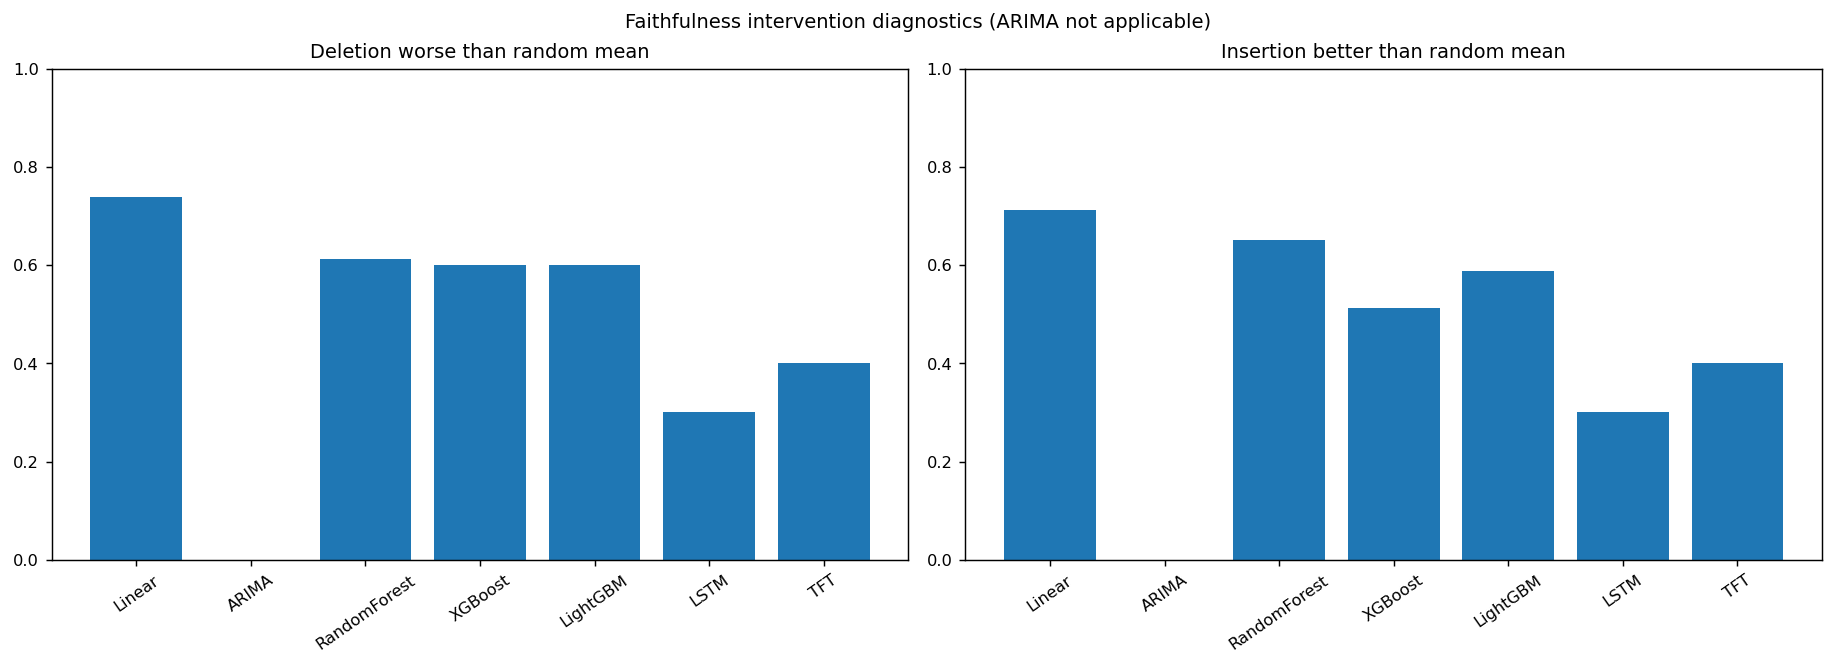

financial_relative_attribution.png


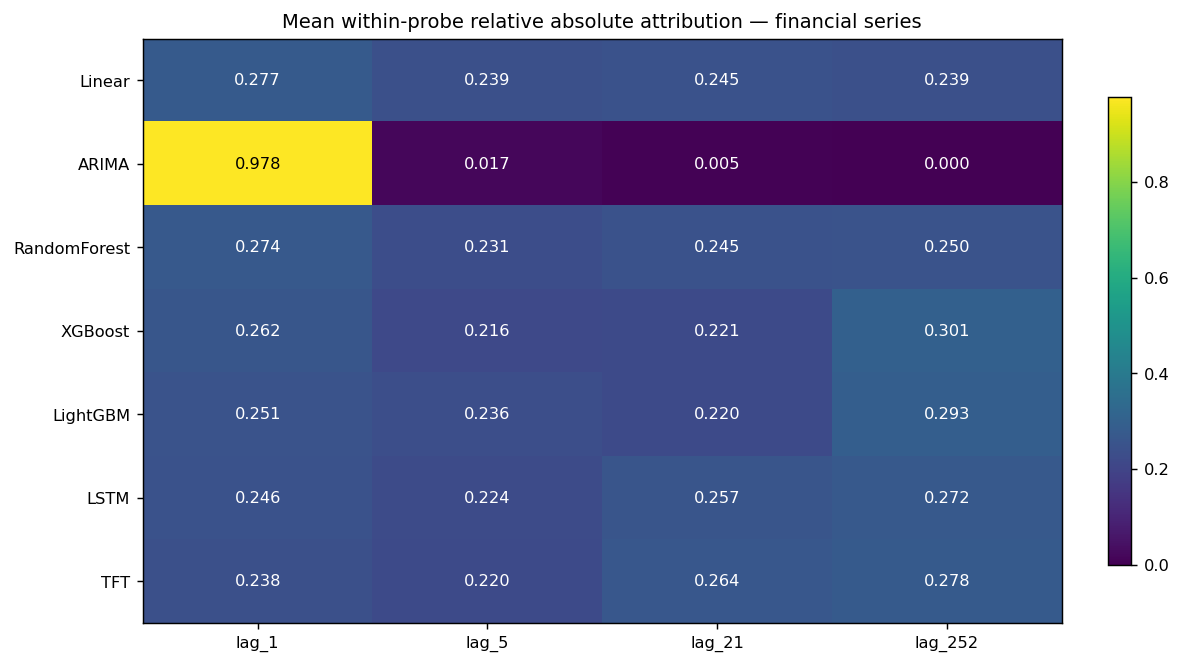

financial_stability_by_regime.png


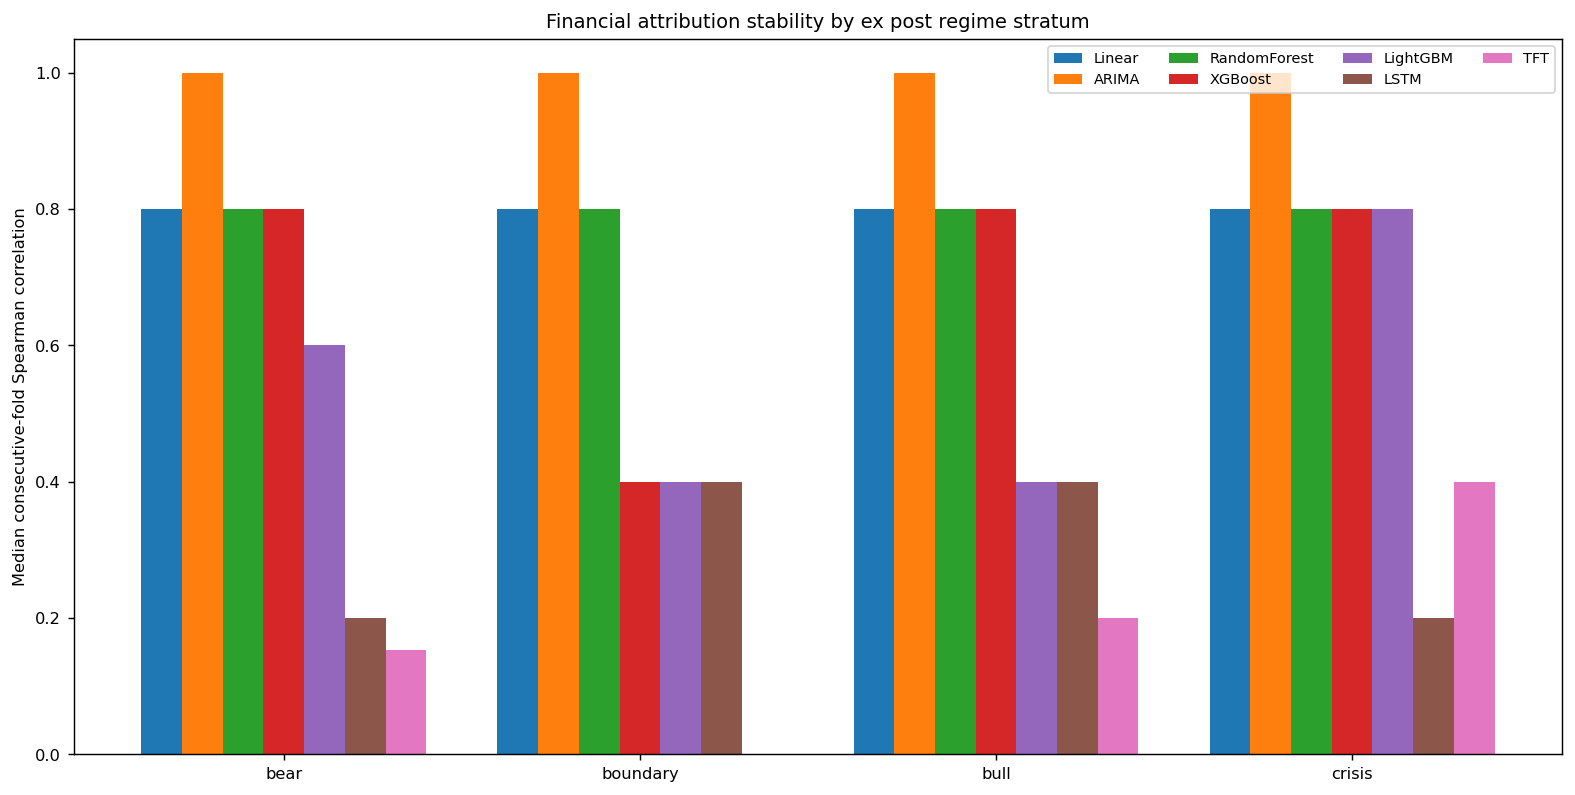

matched_financial_directional_accuracy.png


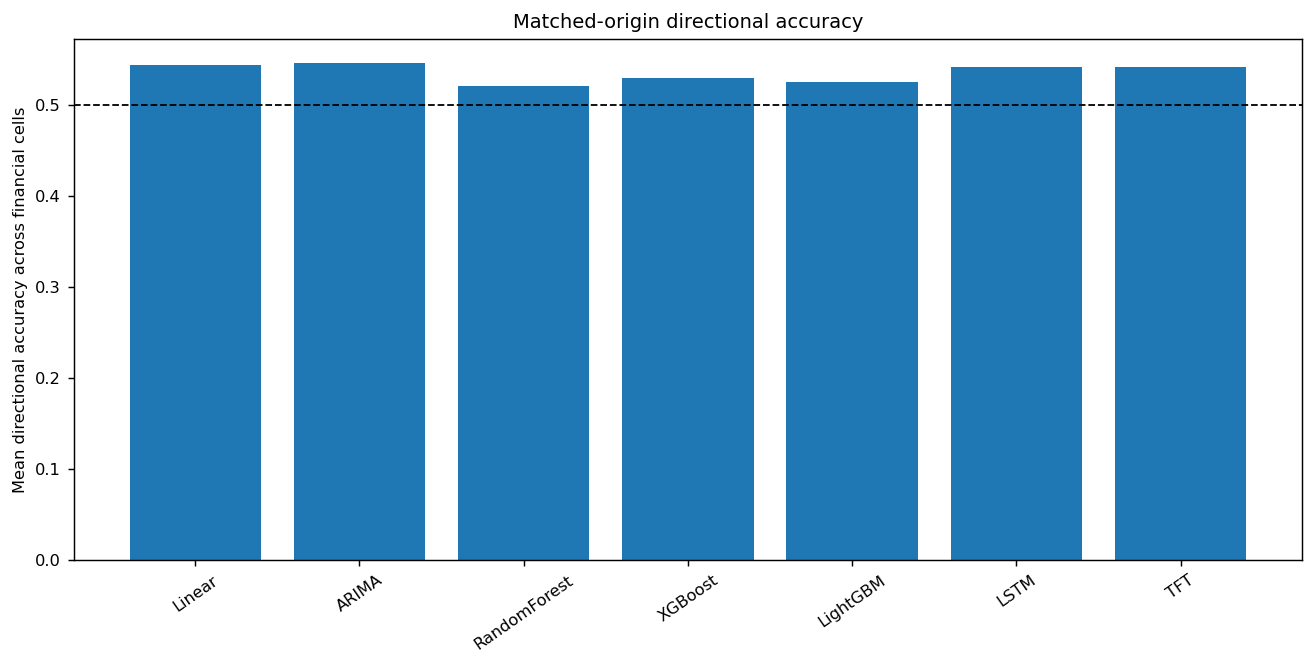

matched_financial_relative_rmse.png


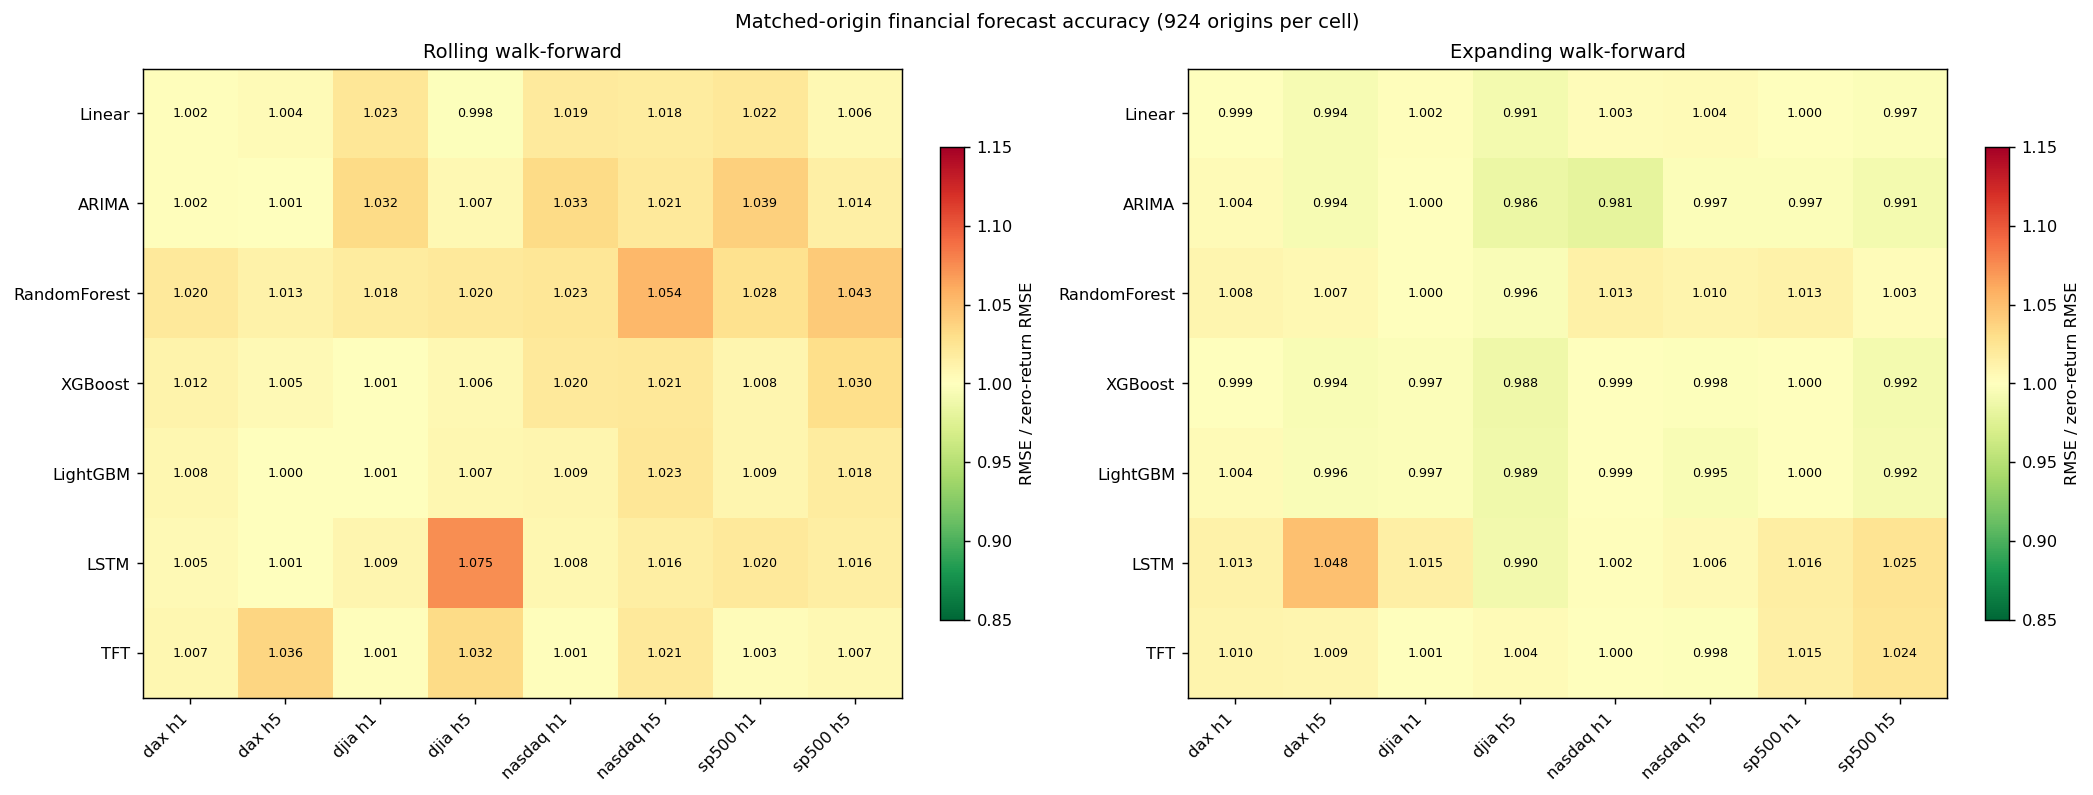

SYNTHESIS READ-BACK VALIDATION: PASS


In [2]:
from IPython.display import Image, display
validation = json.loads((OUT / 'evidence' / 'validation.json').read_text())
assert all(validation.values())
display(pd.read_csv(OUT / 'tables' / 'financial_model_summary.csv').round(6))
display(pd.read_csv(OUT / 'tables' / 'faithfulness_summary.csv').head(30))
for path in sorted((OUT / 'figures').glob('*.png')):
    print(path.name)
    display(Image(filename=str(path)))
print('SYNTHESIS READ-BACK VALIDATION: PASS')